<a href="https://colab.research.google.com/github/JacobSong1/MindWatch-IE08/blob/backend-dev/EDA/notebooks/MW_201_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import userdata
from pathlib import Path
import subprocess
import os

GITHUB_USERNAME = "bakai-work07"
REPO_URL = "https://github.com/JacobSong1/MindWatch-IE08.git"
REPO_DIR = Path("/content/MindWatch-IE08")
BASE_BRANCH = "backend-dev"

token = userdata.get("GITHUB_TOKEN")

if not token:
    raise ValueError("GITHUB_TOKEN was not found in Colab Secrets.")

# Keep credentials only in this temporary Colab runtime
subprocess.run(
    [
        "git", "config", "--global",
        "credential.helper", "cache --timeout=21600"
    ],
    check=True
)

credential = (
    "protocol=https\n"
    "host=github.com\n"
    f"username={GITHUB_USERNAME}\n"
    f"password={token}\n\n"
)

subprocess.run(
    ["git", "credential", "approve"],
    input=credential,
    text=True,
    check=True
)

del token, credential

if (REPO_DIR / ".git").exists():
    subprocess.run(
        ["git", "-C", str(REPO_DIR), "fetch", "origin"],
        check=True
    )
    subprocess.run(
        ["git", "-C", str(REPO_DIR), "switch", BASE_BRANCH],
        check=True
    )
    subprocess.run(
        [
            "git", "-C", str(REPO_DIR),
            "pull", "--ff-only", "origin", BASE_BRANCH
        ],
        check=True
    )
    print("Existing repository updated.")
else:
    subprocess.run(
        [
            "git", "clone",
            "--branch", BASE_BRANCH,
            REPO_URL,
            str(REPO_DIR)
        ],
        check=True
    )
    print("Repository cloned.")

EDA_DIR = REPO_DIR / "EDA"
os.chdir(EDA_DIR)

print("Working directory:", Path.cwd())

subprocess.run(["git", "branch", "--show-current"], check=True)
subprocess.run(["git", "status", "--short"], check=True)

Existing repository updated.
Working directory: /content/MindWatch-IE08/EDA


CompletedProcess(args=['git', 'status', '--short'], returncode=0)

In [ ]:
!git status
!git branch --show-current
!ls

On branch backend-dev
Your branch is up to date with 'origin/backend-dev'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	eda_summary.md

nothing added to commit but untracked files present (use "git add" to track)
backend-dev
data  eda_summary.md  notebooks  README.md  requirements.txt


# MW-201: Exploratory Data Analysis

## Objective

This notebook examines wearable-derived physiological measures and
self-reported stress for 35 students. It evaluates data quality, temporal
patterns, relationships between measures, and potential physiological–
perceived stress mismatch.

In [ ]:
from pathlib import Path
from google.colab import drive
drive.mount("/content/drive")

DATA_ROOT = Path(
    "/content/drive/MyDrive/MindWatch/SSAQS"
)

if not DATA_ROOT.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_ROOT}")

participant_dirs = sorted(
    [
        path for path in DATA_ROOT.iterdir()
        if path.is_dir() and path.name.isdigit()
    ],
    key=lambda path: int(path.name)
)

print("Participant folders:", len(participant_dirs))
print("First folders:", [p.name for p in participant_dirs[:35]])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Participant folders: 35
First folders: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35']


In [ ]:
import pandas as pd

EXPECTED_FILES = [
    "activity_level.csv",
    "daily_questions.csv",
    "hrv.csv",
    "oxygen.csv",
    "sleep.csv",
    "steps.csv",
    "stress.csv",
]

inventory_rows = []

for participant_dir in participant_dirs:
    for filename in EXPECTED_FILES:
        path = participant_dir / filename

        if path.exists():
            df = pd.read_csv(path)

            inventory_rows.append({
                "participant_id": participant_dir.name,
                "file": filename,
                "exists": True,
                "rows": len(df),
                "columns": len(df.columns),
                "duplicate_rows": int(df.duplicated().sum()),
            })
        else:
            inventory_rows.append({
                "participant_id": participant_dir.name,
                "file": filename,
                "exists": False,
                "rows": 0,
                "columns": 0,
                "duplicate_rows": None,
            })

inventory = pd.DataFrame(inventory_rows)

display(
    inventory.groupby("file").agg(
        participants_present=("exists", "sum"),
        total_rows=("rows", "sum"),
        median_rows=("rows", "median"),
        duplicate_rows=("duplicate_rows", "sum"),
    )
)

,participants_present,total_rows,median_rows,duplicate_rows
file,,,,
activity_level.csv,32,1766244,48506.0,0.0
daily_questions.csv,35,3133,103.0,0.0
hrv.csv,32,151243,4375.0,0.0
oxygen.csv,32,978367,27540.0,0.0
sleep.csv,32,1829,49.0,0.0
steps.csv,32,658894,18029.0,0.0
stress.csv,32,1777,49.0,0.0


In [ ]:
print((DATA_ROOT / "course-details.csv").exists())
print((DATA_ROOT / "users-courses.csv").exists())

True
True


In [ ]:
for filename in EXPECTED_FILES:
    examples = [
        participant_dir / filename
        for participant_dir in participant_dirs
        if (participant_dir / filename).exists()
    ]

    if not examples:
        print(f"\n{filename}: NOT FOUND")
        continue

    sample = pd.read_csv(examples[0])

    time_columns = [
        column for column in sample.columns
        if "time" in column.lower() or "date" in column.lower()
    ]

    print(f"\n--- {filename} ---")
    print("Columns:", sample.columns.tolist())
    print("Dtypes:")
    print(sample.dtypes.astype(str).to_dict())

    if time_columns:
        print("Timestamp samples:")
        print(sample[time_columns].head(3).to_dict("records"))


--- activity_level.csv ---
Columns: ['timestamp', 'level']
Dtypes:
{'timestamp': 'object', 'level': 'object'}
Timestamp samples:
[{'timestamp': '2025-02-21T12:58:00Z'}, {'timestamp': '2025-02-21T12:59:00Z'}, {'timestamp': '2025-02-21T13:00:00Z'}]

--- daily_questions.csv ---
Columns: ['timeStampScheduled', 'timeStampSent', 'timeStampStart', 'timeStampStop', 'originalTimeStampSent', 'timeZoneOffset', 'deltaUTC', 'stress', 'anxiety']
Dtypes:
{'timeStampScheduled': 'int64', 'timeStampSent': 'int64', 'timeStampStart': 'int64', 'timeStampStop': 'int64', 'originalTimeStampSent': 'int64', 'timeZoneOffset': 'int64', 'deltaUTC': 'int64', 'stress': 'int64', 'anxiety': 'int64'}
Timestamp samples:
[{'timeStampScheduled': 1739999335, 'timeStampSent': 1739999336, 'timeStampStart': 1740000118, 'timeStampStop': 1740000146, 'originalTimeStampSent': 0, 'timeZoneOffset': -21600}, {'timeStampScheduled': 1740082074, 'timeStampSent': 1740082078, 'timeStampStart': 1740082084, 'timeStampStop': 1740082096, 'o

In [ ]:
def load_participant_file(filename):
    frames = []

    for participant_dir in participant_dirs:
        path = participant_dir / filename

        if not path.exists():
            continue

        df = pd.read_csv(path)
        df.insert(0, "participant_id", participant_dir.name)
        frames.append(df)

    if not frames:
        return pd.DataFrame()

    return pd.concat(frames, ignore_index=True)


questions = load_participant_file("daily_questions.csv")
hrv = load_participant_file("hrv.csv")
sleep = load_participant_file("sleep.csv")
steps = load_participant_file("steps.csv")
activity = load_participant_file("activity_level.csv")
fitbit_stress = load_participant_file("stress.csv")
oxygen = load_participant_file("oxygen.csv")

In [ ]:
import pandas as pd
import numpy as np

# Work on copies so the raw loaded tables remain unchanged
questions = questions.copy()
hrv = hrv.copy()
sleep = sleep.copy()
steps = steps.copy()
activity = activity.copy()
fitbit_stress = fitbit_stress.copy()
oxygen = oxygen.copy()

In [ ]:
UNIX_COLUMNS = [
    "timeStampScheduled",
    "timeStampSent",
    "timeStampStart",
    "timeStampStop",
    "originalTimeStampSent",
]

for column in UNIX_COLUMNS:
    # Treat zero as a missing timestamp, not 1970-01-01
    valid_values = questions[column].where(questions[column] != 0)

    questions[f"{column}_utc"] = pd.to_datetime(
        valid_values,
        unit="s",
        utc=True,
        errors="coerce",
    )

questions["utc_offset"] = pd.to_timedelta(
    questions["timeZoneOffset"],
    unit="s",
)

questions["checkin_start_utc"] = questions["timeStampStart_utc"]
questions["checkin_stop_utc"] = questions["timeStampStop_utc"]

# Local wall-clock time using each record's UTC offset
questions["checkin_local"] = (
    questions["checkin_start_utc"] + questions["utc_offset"]
).dt.tz_localize(None)

questions["local_date"] = questions["checkin_local"].dt.normalize()

questions["checkin_duration_seconds"] = (
    questions["checkin_stop_utc"]
    - questions["checkin_start_utc"]
).dt.total_seconds()

display(
    questions[
        [
            "participant_id",
            "checkin_start_utc",
            "timeZoneOffset",
            "checkin_local",
            "local_date",
            "stress",
        ]
    ].head()
)

,participant_id,checkin_start_utc,timeZoneOffset,checkin_local,local_date,stress
0,1,2025-02-19 21:21:58+00:00,-21600,2025-02-19 15:21:58,2025-02-19,15
1,1,2025-02-20 20:08:04+00:00,-21600,2025-02-20 14:08:04,2025-02-20,33
2,1,2025-02-21 21:52:39+00:00,-21600,2025-02-21 15:52:39,2025-02-21,12
3,1,2025-02-22 21:36:12+00:00,-21600,2025-02-22 15:36:12,2025-02-22,9
4,1,2025-02-23 20:08:45+00:00,-21600,2025-02-23 14:08:45,2025-02-23,4


In [ ]:
for dataframe in [activity, steps, sleep, oxygen]:
    dataframe["timestamp_utc"] = pd.to_datetime(
        dataframe["timestamp"],
        utc=True,
        errors="coerce",
    )

In [ ]:
hrv["timestamp_naive"] = pd.to_datetime(
    hrv["timestamp"],
    errors="coerce",
)

hrv["provisional_date"] = hrv["timestamp_naive"].dt.normalize()

In [ ]:
fitbit_stress["fitbit_date"] = pd.to_datetime(
    fitbit_stress["DATE"],
    errors="coerce",
).dt.normalize()

fitbit_stress["updated_at_naive"] = pd.to_datetime(
    fitbit_stress["UPDATED_AT"],
    errors="coerce",
)

fitbit_stress["fitbit_stress_score"] = (
    fitbit_stress["STRESS_SCORE"].astype(float)
)

fitbit_stress.loc[
    fitbit_stress["CALCULATION_FAILED"],
    "fitbit_stress_score",
] = np.nan

In [ ]:
print("QUESTIONNAIRE TIMEZONE COMBINATIONS")
display(
    questions.groupby(
        ["timeZoneOffset", "deltaUTC"],
        dropna=False,
    )
    .size()
    .rename("rows")
    .reset_index()
    .sort_values("rows", ascending=False)
    .head(30)
)

print("\nACTIVITY LEVEL VALUES")
display(
    activity["level"]
    .value_counts(dropna=False)
    .rename_axis("level")
    .reset_index(name="rows")
)

print("\nFITBIT STRESS VALIDITY")
display(
    fitbit_stress.groupby(
        ["CALCULATION_FAILED", "STRESS_SCORE"],
        dropna=False,
    )
    .size()
    .rename("rows")
    .reset_index()
    .sort_values(
        ["CALCULATION_FAILED", "STRESS_SCORE"]
    )
)

print("\nHRV COVERAGE")
display(hrv["coverage"].describe())

print("\nHRV RMSSD")
display(hrv["rmssd"].describe())

print("\nSLEEP")
display(
    sleep[
        ["overall_score", "deep_sleep_in_minutes"]
    ].describe()
)

print("\nREPORTED STRESS")
display(questions["stress"].describe())

QUESTIONNAIRE TIMEZONE COMBINATIONS


,timeZoneOffset,deltaUTC,rows
16,-21600,0,2480
15,-21600,-1,418
14,-21600,-2,65
17,-21600,1,53
18,-21600,2,18
1,-25200,0,17
13,-21600,-3,9
19,-21600,3,6
23,-21600,11,5
40,7200,0,5



ACTIVITY LEVEL VALUES


,level,rows
0,SEDENTARY,1059736
1,LIGHTLY_ACTIVE,497944
2,MODERATELY_ACTIVE,123458
3,VERY_ACTIVE,85106



FITBIT STRESS VALIDITY


,CALCULATION_FAILED,STRESS_SCORE,rows
0,False,0,9
1,False,56,1
2,False,57,1
3,False,58,2
4,False,59,2
5,False,60,6
6,False,61,7
7,False,62,11
8,False,63,12
9,False,64,20


... (4 outputs left out)


SLEEP


,overall_score,deep_sleep_in_minutes
count,1829.000000,1829.000000
mean,75.547294,76.396391
std,8.282458,25.543369
min,40.000000,5.000000
25%,71.000000,59.000000
50%,76.000000,76.000000
75%,81.000000,93.000000
max,94.000000,177.000000



REPORTED STRESS


,stress
count,3133.000000
mean,33.232046
std,25.687347
min,0.000000
25%,13.000000
50%,26.000000
75%,49.000000
max,100.000000


In [ ]:
quality_checks = pd.Series({
    "questionnaire_rows": len(questions),
    "questionnaire_participants":
        questions["participant_id"].nunique(),

    "missing_checkin_start":
        questions["checkin_start_utc"].isna().sum(),

    "stop_before_start":
        (
            questions["checkin_stop_utc"]
            < questions["checkin_start_utc"]
        ).sum(),

    "nonpositive_checkin_duration":
        (questions["checkin_duration_seconds"] <= 0).sum(),

    "duplicate_checkin_start":
        questions.duplicated(
            ["participant_id", "checkin_start_utc"]
        ).sum(),

    "missing_reported_stress":
        questions["stress"].isna().sum(),

    "stress_below_0":
        (questions["stress"] < 0).sum(),

    "stress_above_100":
        (questions["stress"] > 100).sum(),

    "unparsed_activity_timestamp":
        activity["timestamp_utc"].isna().sum(),

    "unparsed_steps_timestamp":
        steps["timestamp_utc"].isna().sum(),

    "unparsed_sleep_timestamp":
        sleep["timestamp_utc"].isna().sum(),

    "unparsed_hrv_timestamp":
        hrv["timestamp_naive"].isna().sum(),

    "nonpositive_hrv":
        (hrv["rmssd"] <= 0).sum(),

    "failed_fitbit_scores":
        fitbit_stress["CALCULATION_FAILED"].sum(),

    "nonfailed_zero_fitbit_scores":
        (
            (~fitbit_stress["CALCULATION_FAILED"])
            & (fitbit_stress["STRESS_SCORE"] == 0)
        ).sum(),
})

display(quality_checks.to_frame("value"))

,value
questionnaire_rows,3133
questionnaire_participants,35
missing_checkin_start,0
stop_before_start,0
nonpositive_checkin_duration,0
duplicate_checkin_start,0
missing_reported_stress,0
stress_below_0,0
stress_above_100,0
unparsed_activity_timestamp,0


In [ ]:
questionnaire_frequency = (
    questions.groupby(
        ["participant_id", "local_date"]
    )
    .size()
    .rename("checkins_per_day")
    .reset_index()
)

print("Check-ins per participant-day:")
display(
    questionnaire_frequency["checkins_per_day"]
    .value_counts()
    .sort_index()
    .rename_axis("checkins_per_day")
    .reset_index(name="participant_days")
)

print("Check-in local hour distribution:")
display(
    questions["checkin_local"]
    .dt.hour
    .value_counts()
    .sort_index()
    .rename_axis("local_hour")
    .reset_index(name="checkins")
)

Check-ins per participant-day:


,checkins_per_day,participant_days
0,1,3131
1,2,1


Check-in local hour distribution:


,local_hour,checkins
0,0,1
1,6,1
2,12,2
3,13,8
4,14,780
5,15,1436
6,16,684
7,17,195
8,18,20
9,19,2


In [ ]:
# Unique identifier for each questionnaire/check-in
questions = questions.reset_index(drop=True)
questions["checkin_id"] = np.arange(len(questions))

# Actual UTC time corresponding to local midnight
questions["local_day_start_utc"] = (
    pd.to_datetime(
        questions["local_date"],
        utc=True,
    )
    - questions["utc_offset"]
)

# HRV: nonpositive RMSSD cannot be physiologically interpreted
hrv["rmssd_clean"] = hrv["rmssd"].where(
    hrv["rmssd"] > 0
)

# Sleep rows without parseable timestamps cannot be aligned
sleep["valid_timestamp"] = sleep["timestamp_utc"].notna()

# Fitbit comparator: failed calculations are missing
fitbit_stress["fitbit_stress_score_clean"] = (
    fitbit_stress["STRESS_SCORE"].astype(float)
)

fitbit_stress.loc[
    fitbit_stress["CALCULATION_FAILED"],
    "fitbit_stress_score_clean",
] = np.nan

In [ ]:
print("UNPARSEABLE SLEEP TIMESTAMPS")
display(
    sleep.loc[
        sleep["timestamp_utc"].isna(),
        [
            "participant_id",
            "timestamp",
            "overall_score",
            "deep_sleep_in_minutes",
        ],
    ]
)

print("\nNONPOSITIVE HRV VALUES")
display(
    hrv.loc[
        hrv["rmssd"] <= 0,
        [
            "participant_id",
            "timestamp",
            "rmssd",
            "coverage",
        ],
    ]
)

print("\nNON-FAILED FITBIT ZERO SCORES")
display(
    fitbit_stress.loc[
        (~fitbit_stress["CALCULATION_FAILED"])
        & (fitbit_stress["STRESS_SCORE"] == 0),
        [
            "participant_id",
            "DATE",
            "STRESS_SCORE",
            "CALCULATION_FAILED",
        ],
    ]
)

print("\nHRV COVERAGE OUTSIDE 0–1")
display(
    pd.Series({
        "coverage_below_0": (hrv["coverage"] < 0).sum(),
        "coverage_above_1": (hrv["coverage"] > 1).sum(),
        "coverage_missing": hrv["coverage"].isna().sum(),
    }).to_frame("rows")
)

UNPARSEABLE SLEEP TIMESTAMPS


,participant_id,timestamp,overall_score,deep_sleep_in_minutes
877,20,2025-05-12T07:59:28.463Z,67,77
886,20,2025-05-28T10:58:05.456Z,79,124
1268,27,2025-04-07T06:05:31.442Z,77,46
1272,27,2025-04-11T06:59:41.713Z,81,62
1276,27,2025-04-15T06:29:32.632Z,77,64
1287,27,2025-04-28T05:48:18.223Z,73,46
1291,27,2025-05-02T08:20:01.774Z,77,71



NONPOSITIVE HRV VALUES


,participant_id,timestamp,rmssd,coverage
1876,1,2025-04-04T04:55:00,0.0,0.800
2324,1,2025-04-18T00:20:00,0.0,0.709
3892,4,2025-02-27T07:25:00,0.0,0.704
58641,17,2025-03-05T07:20:00,0.0,0.751
58642,17,2025-03-05T07:25:00,0.0,0.902
71903,20,2025-05-04T02:55:00,0.0,0.710
101512,26,2025-05-13T22:05:00,0.0,0.739
115524,28,2025-05-23T01:45:00,0.0,0.702
124920,30,2025-05-09T05:50:00,0.0,0.707
136310,33,2025-04-17T08:10:00,0.0,0.705



NON-FAILED FITBIT ZERO SCORES


,participant_id,DATE,STRESS_SCORE,CALCULATION_FAILED
71,5,2025-03-25T00:00:00,0,False
206,7,2025-03-25T00:00:00,0,False
288,8,2025-03-25T00:00:00,0,False
610,16,2025-03-25T00:00:00,0,False
681,18,2025-03-25T00:00:00,0,False
975,24,2025-03-25T00:00:00,0,False
1116,26,2025-03-25T00:00:00,0,False
1408,30,2025-03-25T00:00:00,0,False
1519,32,2025-03-25T00:00:00,0,False



HRV COVERAGE OUTSIDE 0–1


,rows
coverage_below_0,0
coverage_above_1,42332
coverage_missing,0


In [ ]:
offset_summary = (
    questions.groupby("participant_id")
    .agg(
        questionnaire_rows=("checkin_id", "size"),
        number_of_offsets=("timeZoneOffset", "nunique"),
        offsets=(
            "timeZoneOffset",
            lambda values: sorted(values.unique().tolist()),
        ),
        first_checkin=("checkin_start_utc", "min"),
        last_checkin=("checkin_start_utc", "max"),
    )
    .reset_index()
)

display(
    offset_summary.sort_values(
        ["number_of_offsets", "participant_id"],
        ascending=[False, True],
    )
)

print("Records not using UTC-6:")
display(
    questions.loc[
        questions["timeZoneOffset"] != -21600,
        [
            "participant_id",
            "checkin_start_utc",
            "timeZoneOffset",
            "deltaUTC",
            "checkin_local",
        ],
    ].sort_values(
        ["participant_id", "checkin_start_utc"]
    )
)

,participant_id,questionnaire_rows,number_of_offsets,offsets,first_checkin,last_checkin
0,1,121,2,"[-25200, -21600]",2025-02-19 21:21:58+00:00,2025-06-22 21:12:29+00:00
2,11,39,2,"[-25200, -21600]",2025-02-25 21:43:27+00:00,2025-05-15 21:16:41+00:00
6,15,59,2,"[-21600, -18000]",2025-02-24 22:12:54+00:00,2025-06-07 21:36:23+00:00
7,16,71,2,"[-21600, -14400]",2025-02-17 20:57:02+00:00,2025-06-19 20:45:43+00:00
10,19,116,2,"[-25200, -21600]",2025-02-19 22:15:19+00:00,2025-06-23 21:18:24+00:00
12,20,100,2,"[-25200, -21600]",2025-02-19 21:37:45+00:00,2025-06-20 20:19:33+00:00
18,26,102,2,"[-21600, 7200]",2025-03-06 21:07:02+00:00,2025-07-02 20:57:00+00:00
29,4,118,2,"[-25200, -21600]",2025-02-14 21:07:47+00:00,2025-06-13 20:31:03+00:00
33,8,104,2,"[-25200, -21600]",2025-02-17 21:01:56+00:00,2025-06-11 22:34:31+00:00
1,10,115,1,[-21600],2025-02-20 21:10:06+00:00,2025-06-22 22:45:03+00:00


Records not using UTC-6:


,participant_id,checkin_start_utc,timeZoneOffset,deltaUTC,checkin_local
46,1,2025-04-08 19:39:37+00:00,-25200,-1,2025-04-08 12:39:37
47,1,2025-04-09 22:04:31+00:00,-25200,0,2025-04-09 15:04:31
48,1,2025-04-10 20:04:18+00:00,-25200,0,2025-04-10 13:04:18
1001,11,2025-04-13 20:22:32+00:00,-25200,0,2025-04-13 13:22:32
1002,11,2025-04-14 20:19:50+00:00,-25200,0,2025-04-14 13:19:50
1235,15,2025-04-16 22:21:27+00:00,-18000,2,2025-04-16 17:21:27
1236,15,2025-04-18 21:29:34+00:00,-18000,1,2025-04-18 16:29:34
1237,15,2025-04-19 21:05:06+00:00,-18000,0,2025-04-19 16:05:06
1290,16,2025-04-11 23:44:50+00:00,-14400,0,2025-04-11 19:44:50
1291,16,2025-04-12 23:26:19+00:00,-14400,0,2025-04-12 19:26:19


In [ ]:
activity_sorted = activity.sort_values(
    ["participant_id", "timestamp_utc"]
).copy()

activity_sorted["interval_minutes"] = (
    activity_sorted.groupby("participant_id")[
        "timestamp_utc"
    ]
    .diff()
    .dt.total_seconds()
    .div(60)
)

display(
    activity_sorted.loc[
        activity_sorted["interval_minutes"].between(0, 10),
        "interval_minutes",
    ].value_counts().sort_index().head(15)
)

,count
interval_minutes,
0.016667,6
0.050000,1
0.066667,6
0.083333,2
0.100000,5
0.116667,5
0.133333,3
0.150000,5
0.166667,1


In [ ]:
modal_offsets = (
    questions.groupby("participant_id")["timeZoneOffset"]
    .agg(lambda values: values.mode().iloc[0])
    .rename("modal_offset_seconds")
)

hrv_time_audit = hrv.merge(
    modal_offsets,
    on="participant_id",
    how="left",
)

hrv_time_audit["modal_offset"] = pd.to_timedelta(
    hrv_time_audit["modal_offset_seconds"],
    unit="s",
)

# Hypothesis A: the stored HRV timestamp is local wall-clock time
hrv_time_audit["hour_if_local"] = (
    hrv_time_audit["timestamp_naive"].dt.hour
)

# Hypothesis B: the stored HRV timestamp is UTC without the Z suffix
hrv_time_audit["local_time_if_utc"] = (
    hrv_time_audit["timestamp_naive"].dt.tz_localize("UTC")
    + hrv_time_audit["modal_offset"]
)

hrv_time_audit["hour_if_utc"] = (
    hrv_time_audit["local_time_if_utc"].dt.hour
)

display(
    pd.DataFrame({
        "stored_as_local": (
            hrv_time_audit["hour_if_local"]
            .value_counts()
            .sort_index()
        ),
        "stored_as_utc": (
            hrv_time_audit["hour_if_utc"]
            .value_counts()
            .sort_index()
        ),
    }).fillna(0)
)

,stored_as_local,stored_as_utc
0,11123,13715
1,15996,10107
2,18714,6777
3,20045,4173
4,20487,2167
5,17773,971
6,13715,517
7,10107,273
8,6777,140
9,4173,77


In [ ]:
analysis = questions[
    [
        "checkin_id",
        "participant_id",
        "checkin_start_utc",
        "checkin_local",
        "local_date",
        "local_day_start_utc",
        "utc_offset",
        "stress",
    ]
].copy()

print("Analysis rows:", len(analysis))
print("Participants:", analysis["participant_id"].nunique())

Analysis rows: 3133
Participants: 35


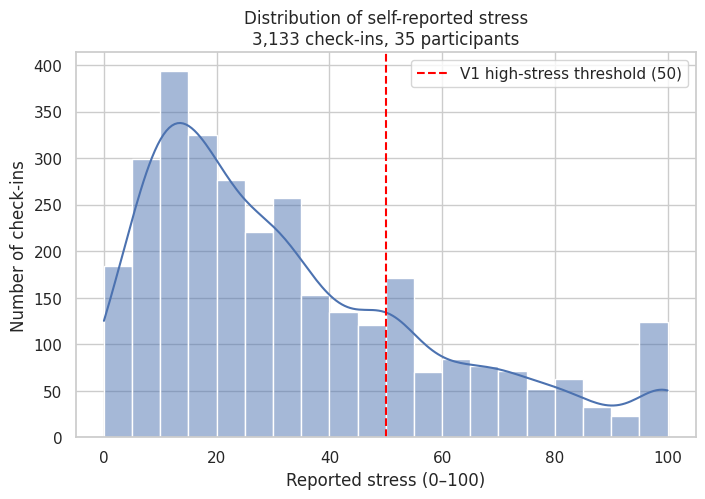

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))

sns.histplot(
    data=analysis,
    x="stress",
    bins=20,
    kde=True,
)

plt.axvline(
    50,
    color="red",
    linestyle="--",
    label="V1 high-stress threshold (50)",
)

plt.title(
    "Distribution of self-reported stress\n"
    f"{len(analysis):,} check-ins, "
    f"{analysis['participant_id'].nunique()} participants"
)
plt.xlabel("Reported stress (0–100)")
plt.ylabel("Number of check-ins")
plt.legend()
plt.show()

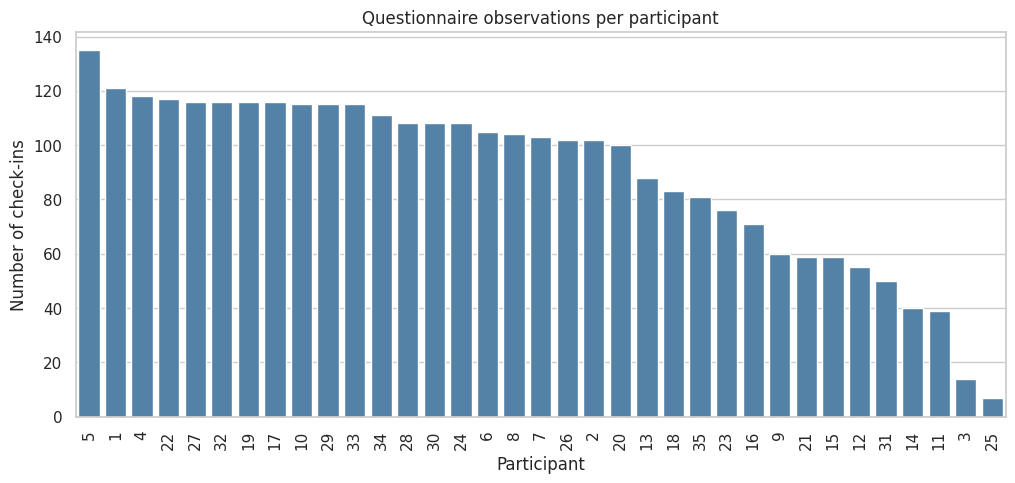

,checkins
count,35.000000
mean,89.514286
std,32.342261
min,7.000000
25%,65.500000
50%,103.000000
75%,115.000000
max,135.000000


In [ ]:
observations_per_participant = (
    analysis.groupby("participant_id")
    .size()
    .sort_values(ascending=False)
    .rename("checkins")
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=observations_per_participant,
    x="participant_id",
    y="checkins",
    color="steelblue",
)

plt.title("Questionnaire observations per participant")
plt.xlabel("Participant")
plt.ylabel("Number of check-ins")
plt.xticks(rotation=90)
plt.show()

display(observations_per_participant.describe())

In [ ]:
threshold_results = []

for threshold in [40, 50, 60]:
    high = analysis["stress"] >= threshold

    threshold_results.append({
        "threshold": threshold,
        "high_stress_checkins": int(high.sum()),
        "percentage": high.mean() * 100,
        "participants_with_high_stress": (
            analysis.loc[high, "participant_id"].nunique()
        ),
    })

display(pd.DataFrame(threshold_results))

,threshold,high_stress_checkins,percentage,participants_with_high_stress
0,40,1024,32.684328,35
1,50,768,24.513246,35
2,60,527,16.820938,34


In [ ]:
import numpy as np
import pandas as pd

# Mixed ISO formats include timestamps with fractional seconds.
sleep_fixed = sleep.copy()
sleep_fixed["timestamp_utc"] = pd.to_datetime(
    sleep_fixed["timestamp"],
    format="mixed",
    utc=True,
    errors="coerce",
)

print("Sleep timestamps missing before:", sleep["timestamp_utc"].isna().sum())
print("Sleep timestamps missing after:", sleep_fixed["timestamp_utc"].isna().sum())

assert sleep_fixed["timestamp_utc"].notna().all(), (
    "Some sleep timestamps still need inspection."
)

# Rebuild from questions so this cell can be rerun without duplicate columns.
feature_table = questions[
    [
        "checkin_id",
        "participant_id",
        "checkin_start_utc",
        "checkin_local",
        "local_date",
        "local_day_start_utc",
        "utc_offset",
        "stress",
    ]
].copy()

assert feature_table["checkin_id"].is_unique
assert feature_table["checkin_start_utc"].notna().all()
assert feature_table["stress"].between(0, 100).all()

# A fixed check-in offset is only an approximation of local midnight
# if the offset changed during that day.
offset_counts = questions.groupby("participant_id")["timeZoneOffset"].nunique()

feature_table["participant_has_multiple_offsets"] = (
    feature_table["participant_id"].map(offset_counts).gt(1)
)

feature_table["hours_since_local_midnight"] = (
    feature_table["checkin_start_utc"]
    - feature_table["local_day_start_utc"]
).dt.total_seconds() / 3600

assert feature_table["hours_since_local_midnight"].between(
    0, 24, inclusive="left"
).all()

# Preserve an explicit audit flag without adding Fitbit scores as predictors.
fitbit_stress["suspect_nonfailed_zero"] = (
    ~fitbit_stress["CALCULATION_FAILED"]
    & fitbit_stress["STRESS_SCORE"].eq(0)
)

print("Check-ins:", len(feature_table))
print("Participants:", feature_table["participant_id"].nunique())

Sleep timestamps missing before: 7
Sleep timestamps missing after: 0
Check-ins: 3133
Participants: 35


In [ ]:
ACTIVITY_LEVELS = [
    "SEDENTARY",
    "LIGHTLY_ACTIVE",
    "MODERATELY_ACTIVE",
    "VERY_ACTIVE",
]

def prepare_stream(df, time_col, value_cols, name):
    """Remove identical records; stop if a timestamp has conflicting values."""
    out = df[
        ["participant_id", time_col] + value_cols
    ].copy()

    assert out[time_col].notna().all(), f"{name}: missing timestamps"

    before = len(out)
    out = out.drop_duplicates()

    conflicting = out.duplicated(
        ["participant_id", time_col], keep=False
    )

    if conflicting.any():
        display(out.loc[conflicting].head(20))
        raise ValueError(
            f"{name}: conflicting records at the same timestamp. "
            "Inspect these before aggregation."
        )

    print(f"{name}: removed {before - len(out)} identical records")
    return out.sort_values(["participant_id", time_col])


steps_ready = prepare_stream(
    steps, "timestamp_utc", ["steps"], "Steps"
)
steps_ready["steps"] = pd.to_numeric(
    steps_ready["steps"], errors="coerce"
)
assert (
    np.isfinite(steps_ready["steps"])
    & steps_ready["steps"].ge(0)
).all(), "Inspect invalid step counts."

steps_ready["record_end_utc"] = (
    steps_ready["timestamp_utc"] + pd.Timedelta(minutes=1)
)


activity_ready = prepare_stream(
    activity, "timestamp_utc", ["level"], "Activity"
)
assert activity_ready["level"].isin(ACTIVITY_LEVELS).all()

activity_ready["minute_start_utc"] = (
    activity_ready["timestamp_utc"].dt.floor("min")
)

activity_minutes = (
    activity_ready
    .groupby(["participant_id", "minute_start_utc"], as_index=False)
    .agg(
        level=("level", "first"),
        distinct_levels=("level", "nunique"),
    )
)

print(
    "Conflicting activity minute bins excluded:",
    activity_minutes["distinct_levels"].gt(1).sum(),
)

activity_minutes = activity_minutes.loc[
    activity_minutes["distinct_levels"].eq(1)
].copy()

activity_minutes["record_end_utc"] = (
    activity_minutes["minute_start_utc"] + pd.Timedelta(minutes=1)
)


sleep_ready = prepare_stream(
    sleep_fixed,
    "timestamp_utc",
    ["overall_score", "deep_sleep_in_minutes"],
    "Sleep",
)


hrv_ready = prepare_stream(
    hrv,
    "timestamp_naive",
    ["rmssd", "coverage"],
    "HRV",
)
hrv_ready["rmssd_clean"] = hrv_ready["rmssd"].where(
    np.isfinite(hrv_ready["rmssd"]) & hrv_ready["rmssd"].gt(0)
)

# Only assign an offset where all questionnaire records agree.
single_offsets = (
    questions.loc[
        questions["participant_id"].map(offset_counts).eq(1)
    ]
    .groupby("participant_id")["timeZoneOffset"]
    .first()
)

hrv_ready["assumed_offset_seconds"] = (
    hrv_ready["participant_id"].map(single_offsets)
)
hrv_ready = hrv_ready.loc[
    hrv_ready["assumed_offset_seconds"].notna()
].copy()

# PROVISIONAL: stored HRV timestamps are local wall-clock timestamps.
hrv_ready["timestamp_utc_assumed"] = (
    hrv_ready["timestamp_naive"].dt.tz_localize("UTC")
    - pd.to_timedelta(hrv_ready["assumed_offset_seconds"], unit="s")
)
hrv_ready["record_end_utc"] = (
    hrv_ready["timestamp_utc_assumed"] + pd.Timedelta(minutes=5)
)

print("HRV alignment assumption: local time, single-offset participants only")

Steps: removed 0 identical records
Activity: removed 0 identical records
Conflicting activity minute bins excluded: 0
Sleep: removed 0 identical records
HRV: removed 0 identical records
HRV alignment assumption: local time, single-offset participants only


In [ ]:
# Group once to avoid repeatedly scanning the entire dataset.
streams = {
    "steps": {p: g for p, g in steps_ready.groupby("participant_id")},
    "activity": {p: g for p, g in activity_minutes.groupby("participant_id")},
    "sleep": {p: g for p, g in sleep_ready.groupby("participant_id")},
    "hrv": {p: g for p, g in hrv_ready.groupby("participant_id")},
}

empty_streams = {
    "steps": steps_ready.iloc[:0],
    "activity": activity_minutes.iloc[:0],
    "sleep": sleep_ready.iloc[:0],
    "hrv": hrv_ready.iloc[:0],
}

def get_stream(name, participant):
    return streams[name].get(participant, empty_streams[name])

rows = []

for q in feature_table.itertuples(index=False):
    participant = q.participant_id
    cutoff = q.checkin_start_utc
    day_start = q.local_day_start_utc

    s = get_stream("steps", participant)
    s = s.loc[
        s["timestamp_utc"].ge(day_start)
        & s["record_end_utc"].lt(cutoff)
    ]

    a = get_stream("activity", participant)
    a = a.loc[
        a["minute_start_utc"].ge(day_start)
        & a["record_end_utc"].lt(cutoff)
    ]

    sl = get_stream("sleep", participant)
    sl = sl.loc[
        sl["timestamp_utc"].ge(cutoff - pd.Timedelta(hours=36))
        & sl["timestamp_utc"].lt(cutoff)
    ].sort_values("timestamp_utc")

    h = get_stream("hrv", participant)
    h = h.loc[
        h["timestamp_utc_assumed"].ge(cutoff - pd.Timedelta(hours=24))
        & h["record_end_utc"].lt(cutoff)
    ]
    hv = h.loc[h["rmssd_clean"].notna()]

    row = {
        "checkin_id": q.checkin_id,

        "steps_precheckin": s["steps"].sum(min_count=1),
        "steps_records_n": len(s),
        "steps_latest_end_utc": s["record_end_utc"].max(),

        "activity_observed_minutes": len(a) if len(a) else np.nan,
        "activity_latest_end_utc": a["record_end_utc"].max(),

        "sleep_overall_score": np.nan,
        "sleep_deep_minutes": np.nan,
        "sleep_age_hours": np.nan,
        "sleep_source_utc": pd.NaT,

        "hrv_rmssd_median_24h_provisional": hv["rmssd_clean"].median(),
        "hrv_valid_records_n": len(hv),
        "hrv_invalid_records_n": len(h) - len(hv),
        "hrv_coverage_median": hv["coverage"].median(),
        "hrv_latest_end_utc": hv["record_end_utc"].max(),

        "hrv_alignment_status": (
            "excluded_multiple_offsets"
            if q.participant_has_multiple_offsets
            else "provisional_local_time"
        ),
    }

    for level in ACTIVITY_LEVELS:
        row[f"{level.lower()}_minutes_precheckin"] = (
            int(a["level"].eq(level).sum()) if len(a) else np.nan
        )

    row["active_minutes_precheckin"] = (
        int(a["level"].isin(ACTIVITY_LEVELS[1:]).sum())
        if len(a) else np.nan
    )

    if len(sl):
        latest_sleep = sl.iloc[-1]
        row.update({
            "sleep_overall_score": latest_sleep["overall_score"],
            "sleep_deep_minutes": latest_sleep["deep_sleep_in_minutes"],
            "sleep_source_utc": latest_sleep["timestamp_utc"],
            "sleep_age_hours": (
                cutoff - latest_sleep["timestamp_utc"]
            ).total_seconds() / 3600,
        })

    rows.append(row)

aligned_features = pd.DataFrame(rows)

# Rerunnable: replace previously generated columns if this cell is rerun.
feature_table = (
    feature_table.drop(
        columns=aligned_features.columns.drop("checkin_id"),
        errors="ignore",
    )
    .merge(
        aligned_features,
        on="checkin_id",
        how="left",
        validate="one_to_one",
    )
)

print("Feature table shape:", feature_table.shape)
display(feature_table.head())

Feature table shape: (3133, 30)


,checkin_id,participant_id,checkin_start_utc,checkin_local,local_date,local_day_start_utc,utc_offset,stress,participant_has_multiple_offsets,hours_since_local_midnight,...,hrv_valid_records_n,hrv_invalid_records_n,hrv_coverage_median,hrv_latest_end_utc,hrv_alignment_status,sedentary_minutes_precheckin,lightly_active_minutes_precheckin,moderately_active_minutes_precheckin,very_active_minutes_precheckin,active_minutes_precheckin
0,0,1,2025-02-19 21:21:58+00:00,2025-02-19 15:21:58,2025-02-19,2025-02-19 06:00:00+00:00,-1 days +18:00:00,15,True,15.366111,...,0,0,NaN,NaT,excluded_multiple_offsets,NaN,NaN,NaN,NaN,NaN
1,1,1,2025-02-20 20:08:04+00:00,2025-02-20 14:08:04,2025-02-20,2025-02-20 06:00:00+00:00,-1 days +18:00:00,33,True,14.134444,...,0,0,NaN,NaT,excluded_multiple_offsets,NaN,NaN,NaN,NaN,NaN
2,2,1,2025-02-21 21:52:39+00:00,2025-02-21 15:52:39,2025-02-21,2025-02-21 06:00:00+00:00,-1 days +18:00:00,12,True,15.877500,...,0,0,NaN,NaT,excluded_multiple_offsets,341.0,71.0,8.0,13.0,92.0
3,3,1,2025-02-22 21:36:12+00:00,2025-02-22 15:36:12,2025-02-22,2025-02-22 06:00:00+00:00,-1 days +18:00:00,9,True,15.603333,...,0,0,NaN,NaT,excluded_multiple_offsets,210.0,73.0,5.0,5.0,83.0
4,4,1,2025-02-23 20:08:45+00:00,2025-02-23 14:08:45,2025-02-23,2025-02-23 06:00:00+00:00,-1 days +18:00:00,4,True,14.145833,...,0,0,NaN,NaT,excluded_multiple_offsets,251.0,85.0,6.0,0.0,91.0


In [ ]:
assert len(feature_table) == len(questions)
assert feature_table["checkin_id"].is_unique

# Check the latest included source timestamp for each stream.
audit_time_columns = [
    "steps_latest_end_utc",
    "activity_latest_end_utc",
    "sleep_source_utc",
    "hrv_latest_end_utc",
]

for column in audit_time_columns:
    feature_table[column] = pd.to_datetime(
        feature_table[column], utc=True
    )
    present = feature_table[column].notna()

    assert (
        feature_table.loc[present, column]
        < feature_table.loc[present, "checkin_start_utc"]
    ).all(), f"Cutoff violation: {column}"

assert feature_table["sleep_age_hours"].dropna().between(0, 36).all()

activity_columns = [
    f"{level.lower()}_minutes_precheckin"
    for level in ACTIVITY_LEVELS
]

observed = feature_table["activity_observed_minutes"].notna()
assert np.allclose(
    feature_table.loc[observed, activity_columns].sum(axis=1),
    feature_table.loc[observed, "activity_observed_minutes"],
)

assert (
    feature_table.loc[observed, "activity_observed_minutes"]
    <= feature_table.loc[observed, "hours_since_local_midnight"] * 60
).all()

feature_columns = [
    "steps_precheckin",
    "active_minutes_precheckin",
    "sleep_overall_score",
    "sleep_deep_minutes",
    "hrv_rmssd_median_24h_provisional",
]

print("MISSINGNESS")
display(
    pd.DataFrame({
        "available_checkins": feature_table[feature_columns].notna().sum(),
        "missing_checkins": feature_table[feature_columns].isna().sum(),
        "missing_percent": (
            feature_table[feature_columns].isna().mean() * 100
        ).round(1),
    })
)

print("FEATURE DISTRIBUTIONS")
display(feature_table[feature_columns].describe().T)

print("HRV ALIGNMENT STATUS")
display(feature_table["hrv_alignment_status"].value_counts())

feature_table["has_all_candidate_features"] = (
    feature_table[feature_columns].notna().all(axis=1)
)

print("AVAILABILITY BY PARTICIPANT")
display(
    feature_table.groupby("participant_id").agg(
        checkins=("checkin_id", "size"),
        with_steps=("steps_precheckin", "count"),
        with_activity=("active_minutes_precheckin", "count"),
        with_sleep=("sleep_overall_score", "count"),
        with_provisional_hrv=("hrv_rmssd_median_24h_provisional", "count"),
        with_all_features=("has_all_candidate_features", "sum"),
    )
)

print("Timing assertions passed under the documented assumptions.")
print("All check-ins retained; missing features have not been imputed.")

MISSINGNESS


,available_checkins,missing_checkins,missing_percent
steps_precheckin,2173,960,30.6
active_minutes_precheckin,2203,930,29.7
sleep_overall_score,1585,1548,49.4
sleep_deep_minutes,1585,1548,49.4
hrv_rmssd_median_24h_provisional,1179,1954,62.4


FEATURE DISTRIBUTIONS


,count,mean,std,min,25%,50%,75%,max
steps_precheckin,2173.0,5521.483203,4131.329658,4.0000,2210.00000,4830.0000,7952.0000,27609.0000
active_minutes_precheckin,2203.0,152.156605,90.733541,0.0000,84.00000,147.0000,210.0000,586.0000
sleep_overall_score,1585.0,75.793060,8.226057,40.0000,71.00000,77.0000,82.0000,93.0000
sleep_deep_minutes,1585.0,77.528076,25.746592,5.0000,60.00000,77.0000,94.0000,177.0000
hrv_rmssd_median_24h_provisional,1179.0,74.528564,36.985917,13.5205,41.38925,69.2725,97.9025,178.1085


HRV ALIGNMENT STATUS


,count
hrv_alignment_status,
provisional_local_time,2303
excluded_multiple_offsets,830


AVAILABILITY BY PARTICIPANT


,checkins,with_steps,with_activity,with_sleep,with_provisional_hrv,with_all_features
participant_id,,,,,,
1,121,103,103,30,0,0
10,115,93,96,44,41,41
11,39,39,39,12,0,0
12,55,0,0,0,0,0
13,88,80,82,74,69,69
14,40,0,0,0,0,0
15,59,30,30,20,0,0
16,71,38,38,35,0,0
17,116,70,72,14,19,13


Timing assertions passed under the documented assumptions.
All check-ins retained; missing features have not been imputed.


In [ ]:
# Fraction of the pre-check-in window with an observed activity minute.
# This is data observation, NOT validated device wear coverage.
feature_table["activity_observed_fraction"] = (
    feature_table["activity_observed_minutes"]
    / (feature_table["hours_since_local_midnight"] * 60).replace(0, np.nan)
)

# Among recorded minutes, what fraction were active?
feature_table["active_fraction_of_observed"] = (
    feature_table["active_minutes_precheckin"]
    / feature_table["activity_observed_minutes"].replace(0, np.nan)
)

print("OBSERVATION QUALITY")
display(
    feature_table[
        [
            "activity_observed_fraction",
            "active_fraction_of_observed",
            "sleep_age_hours",
        ]
    ].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
)

hrv_present = feature_table[
    "hrv_rmssd_median_24h_provisional"
].notna()

print("HRV RECORD COUNTS WHEN AN HRV FEATURE IS PRESENT")
display(
    feature_table.loc[hrv_present, "hrv_valid_records_n"]
    .describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])
    .to_frame()
)

# Sensitivity counts only: these are not validated quality thresholds.
support_rows = []
for minimum_records in [1, 6, 12, 24, 48]:
    keep = (
        hrv_present
        & feature_table["hrv_valid_records_n"].ge(minimum_records)
    )
    support_rows.append({
        "minimum_hrv_records": minimum_records,
        "checkins": int(keep.sum()),
        "participants": feature_table.loc[
            keep, "participant_id"
        ].nunique(),
    })

print("HRV AVAILABILITY AT DIFFERENT RECORD-COUNT REQUIREMENTS")
display(pd.DataFrame(support_rows))

# Separate intentional exclusions from absent aligned HRV.
feature_table["hrv_availability_reason"] = np.select(
    [
        feature_table["participant_has_multiple_offsets"],
        hrv_present,
        feature_table["hrv_invalid_records_n"].gt(0),
    ],
    [
        "Excluded: participant has multiple offsets",
        "Available: provisional local-time alignment",
        "Window contains only invalid RMSSD",
    ],
    default="No HRV records in assumed pre-check-in window",
)

display(
    feature_table["hrv_availability_reason"]
    .value_counts()
    .rename_axis("reason")
    .reset_index(name="checkins")
)

OBSERVATION QUALITY


,count,mean,std,min,5%,25%,50%,75%,95%,max
activity_observed_fraction,2203.0,0.389236,0.171459,0.000965,0.036605,0.279361,0.421613,0.514914,0.626585,0.806979
active_fraction_of_observed,2203.0,0.422151,0.185639,0.000000,0.167467,0.302865,0.401222,0.507532,0.785348,1.000000
sleep_age_hours,1585.0,14.467320,4.700554,0.130833,9.475500,12.446389,14.192222,15.566944,17.790444,35.887222


HRV RECORD COUNTS WHEN AN HRV FEATURE IS PRESENT


,hrv_valid_records_n
count,1179.000000
mean,80.055980
std,21.507063
min,3.000000
5%,47.000000
25%,65.000000
50%,79.000000
75%,94.000000
95%,117.000000
max,151.000000


HRV AVAILABILITY AT DIFFERENT RECORD-COUNT REQUIREMENTS


,minimum_hrv_records,checkins,participants
0,1,1179,23
1,6,1176,23
2,12,1175,23
3,24,1174,23
4,48,1119,23


,reason,checkins
0,Available: provisional local-time alignment,1179
1,No HRV records in assumed pre-check-in window,1124
2,Excluded: participant has multiple offsets,830


In [ ]:
subset_masks = {
    "All check-ins": pd.Series(True, index=feature_table.index),

    "Steps available":
        feature_table["steps_precheckin"].notna(),

    "Activity available":
        feature_table["active_minutes_precheckin"].notna(),

    "Sleep available":
        feature_table["sleep_overall_score"].notna()
        & feature_table["sleep_deep_minutes"].notna(),

    "Provisional HRV available":
        feature_table["hrv_rmssd_median_24h_provisional"].notna(),

    "All five features available":
        feature_table["has_all_candidate_features"],

    "At least one feature missing":
        ~feature_table["has_all_candidate_features"],
}

subset_rows = []

for name, mask in subset_masks.items():
    subset = feature_table.loc[mask]

    subset_rows.append({
        "subset": name,
        "checkins": len(subset),
        "participants": subset["participant_id"].nunique(),
        "stress_mean": subset["stress"].mean(),
        "stress_median": subset["stress"].median(),
        "stress_ge_50_percent": (
            subset["stress"].ge(50).mean() * 100
        ),
        "median_checkin_local_hour": (
            subset["hours_since_local_midnight"].median()
        ),
    })

subset_summary = pd.DataFrame(subset_rows).set_index("subset")
display(subset_summary.round(2))

# Show whether a few participants dominate the complete-feature subset.
complete = feature_table.loc[
    feature_table["has_all_candidate_features"]
]

complete_contributions = (
    complete.groupby("participant_id")
    .size()
    .sort_values(ascending=False)
    .rename("complete_checkins")
    .to_frame()
)

complete_contributions["percent_of_complete_subset"] = (
    complete_contributions["complete_checkins"]
    / max(len(complete), 1) * 100
)

print("PARTICIPANT CONTRIBUTIONS TO THE COMPLETE-FEATURE SUBSET")
display(complete_contributions.round(2))

,checkins,participants,stress_mean,stress_median,stress_ge_50_percent,median_checkin_local_hour
subset,,,,,,
All check-ins,3133,35,33.23,26.0,24.51,15.58
Steps available,2173,32,36.13,30.0,27.66,15.58
Activity available,2203,32,35.97,30.0,27.46,15.58
Sleep available,1585,32,36.42,31.0,27.38,15.51
Provisional HRV available,1179,23,38.90,32.0,32.32,15.56
All five features available,1141,23,38.79,32.0,31.90,15.56
At least one feature missing,1992,35,30.05,22.0,20.28,15.58


PARTICIPANT CONTRIBUTIONS TO THE COMPLETE-FEATURE SUBSET


,complete_checkins,percent_of_complete_subset
participant_id,,
24,99,8.68
5,98,8.59
27,93,8.15
7,84,7.36
32,77,6.75
33,73,6.40
13,69,6.05
30,69,6.05
34,69,6.05


In [ ]:
FEATURE_LABELS = {
    "steps_precheckin": "Recorded steps",
    "active_minutes_precheckin": "Recorded active minutes",
    "active_fraction_of_observed": "Active fraction of observed minutes",
    "sleep_overall_score": "Sleep score",
    "sleep_deep_minutes": "Deep-sleep minutes",
    "hrv_rmssd_median_24h_provisional": "HRV RMSSD (provisional)",
}

def paired_rows(df, feature):
    return (
        df[["participant_id", feature, "stress"]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

def safe_spearman(df, feature):
    if (
        len(df) < 3
        or df[feature].nunique() < 2
        or df["stress"].nunique() < 2
    ):
        return np.nan
    return df[feature].corr(df["stress"], method="spearman")

pooled_rows = []

for feature, label in FEATURE_LABELS.items():
    paired = paired_rows(feature_table, feature)

    pooled_rows.append({
        "feature": label,
        "paired_checkins": len(paired),
        "participants": paired["participant_id"].nunique(),
        "pooled_spearman": safe_spearman(paired, feature),
    })

pooled_correlations = pd.DataFrame(pooled_rows)
display(pooled_correlations.round(3))

,feature,paired_checkins,participants,pooled_spearman
0,Recorded steps,2173,32,0.149
1,Recorded active minutes,2203,32,0.137
2,Active fraction of observed minutes,2203,32,0.055
3,Sleep score,1585,32,0.013
4,Deep-sleep minutes,1585,32,-0.021
5,HRV RMSSD (provisional),1179,23,0.039


In [ ]:
MIN_PAIRED_CHECKINS = 10

participant_rows = []

for feature, label in FEATURE_LABELS.items():
    paired = paired_rows(feature_table, feature)

    for participant, group in paired.groupby("participant_id"):
        if len(group) < MIN_PAIRED_CHECKINS:
            continue

        rho = safe_spearman(group, feature)
        if pd.isna(rho):
            continue

        participant_rows.append({
            "participant_id": participant,
            "feature": label,
            "paired_checkins": len(group),
            "spearman": rho,
        })

participant_correlations = pd.DataFrame(
    participant_rows,
    columns=["participant_id", "feature", "paired_checkins", "spearman"],
)

within_rows = []

for label in FEATURE_LABELS.values():
    group = participant_correlations.loc[
        participant_correlations["feature"].eq(label)
    ]
    values = group["spearman"]

    within_rows.append({
        "feature": label,
        "eligible_participants": len(group),
        "paired_checkins_used": group["paired_checkins"].sum(),
        "median_participant_spearman": values.median(),
        "participant_rho_q25": values.quantile(0.25),
        "participant_rho_q75": values.quantile(0.75),
        "percent_positive": (
            values.gt(0).mean() * 100 if len(values) else np.nan
        ),
    })

within_summary = pd.DataFrame(within_rows)

display(
    pooled_correlations.merge(
        within_summary, on="feature", validate="one_to_one"
    ).round(3)
)

print(
    "Participant correlations are summarised with equal weight per person. "
    "Quartiles describe variation across people, not confidence intervals."
)

,feature,paired_checkins,participants,pooled_spearman,eligible_participants,paired_checkins_used,median_participant_spearman,participant_rho_q25,participant_rho_q75,percent_positive
0,Recorded steps,2173,32,0.149,31,2167,0.081,-0.015,0.134,67.742
1,Recorded active minutes,2203,32,0.137,31,2197,0.053,-0.023,0.163,70.968
2,Active fraction of observed minutes,2203,32,0.055,31,2197,-0.086,-0.161,0.035,29.032
3,Sleep score,1585,32,0.013,30,1572,-0.023,-0.171,0.057,36.667
4,Deep-sleep minutes,1585,32,-0.021,30,1572,-0.044,-0.141,0.031,33.333
5,HRV RMSSD (provisional),1179,23,0.039,20,1158,0.036,-0.077,0.112,65.000


Participant correlations are summarised with equal weight per person. Quartiles describe variation across people, not confidence intervals.


In [ ]:
all_rows = pd.Series(True, index=feature_table.index)
sensitivity_rows = []

def add_sensitivity(feature, rule, mask):
    paired = paired_rows(feature_table.loc[mask], feature)

    sensitivity_rows.append({
        "feature": FEATURE_LABELS[feature],
        "rule": rule,
        "paired_checkins": len(paired),
        "participants": paired["participant_id"].nunique(),
        "pooled_spearman": safe_spearman(paired, feature),
    })


for feature in [
    "active_minutes_precheckin",
    "active_fraction_of_observed",
]:
    add_sensitivity(feature, "All available", all_rows)

    for threshold in [0.25, 0.50]:
        add_sensitivity(
            feature,
            f"Activity observed fraction >= {threshold:.0%}",
            feature_table["activity_observed_fraction"].ge(threshold),
        )


hrv_feature = "hrv_rmssd_median_24h_provisional"
add_sensitivity(hrv_feature, "All available", all_rows)

for minimum in [24, 48]:
    add_sensitivity(
        hrv_feature,
        f"At least {minimum} valid HRV records",
        feature_table["hrv_valid_records_n"].ge(minimum),
    )


for feature in ["sleep_overall_score", "sleep_deep_minutes"]:
    add_sensitivity(feature, "Sleep timestamp within 36 hours", all_rows)

    add_sensitivity(
        feature,
        "Sleep timestamp within 24 hours",
        feature_table["sleep_age_hours"].le(24),
    )

sensitivity_results = pd.DataFrame(sensitivity_rows)
display(sensitivity_results.round(3))

,feature,rule,paired_checkins,participants,pooled_spearman
0,Recorded active minutes,All available,2203,32,0.137
1,Recorded active minutes,Activity observed fraction >= 25%,1731,32,0.117
2,Recorded active minutes,Activity observed fraction >= 50%,636,31,0.059
3,Active fraction of observed minutes,All available,2203,32,0.055
4,Active fraction of observed minutes,Activity observed fraction >= 25%,1731,32,0.017
5,Active fraction of observed minutes,Activity observed fraction >= 50%,636,31,-0.011
6,HRV RMSSD (provisional),All available,1179,23,0.039
7,HRV RMSSD (provisional),At least 24 valid HRV records,1174,23,0.038
8,HRV RMSSD (provisional),At least 48 valid HRV records,1119,23,0.040
9,Sleep score,Sleep timestamp within 36 hours,1585,32,0.013


In [ ]:
# Build a unique target check-in for each participant/local calendar day.
target = feature_table[
    [
        "participant_id",
        "local_date",
        "checkin_start_utc",
        "utc_offset",
        "stress",
    ]
].copy()

target["checkins_on_target_day"] = (
    target.groupby(["participant_id", "local_date"])["stress"]
    .transform("size")
)

print(
    "Ambiguous participant-days excluded as targets:",
    target.loc[
        target["checkins_on_target_day"].gt(1),
        ["participant_id", "local_date"],
    ].drop_duplicates().shape[0],
)

target = target.loc[
    target["checkins_on_target_day"].eq(1)
].rename(columns={
    "local_date": "target_local_date",
    "checkin_start_utc": "next_checkin_utc",
    "utc_offset": "next_utc_offset",
    "stress": "next_day_stress",
})

next_day_pairs = feature_table.copy()
next_day_pairs["target_local_date"] = (
    next_day_pairs["local_date"] + pd.Timedelta(days=1)
)

next_day_pairs = next_day_pairs.merge(
    target,
    on=["participant_id", "target_local_date"],
    how="left",
    validate="many_to_one",
)

matched = next_day_pairs["next_checkin_utc"].notna()
same_offset = next_day_pairs["utc_offset"].eq(
    next_day_pairs["next_utc_offset"]
)
forward_in_time = next_day_pairs["next_checkin_utc"].gt(
    next_day_pairs["checkin_start_utc"]
)

print("Sources with a unique next-calendar-day target:", int(matched.sum()))
print(
    "Matched pairs excluded for different offsets:",
    int((matched & ~same_offset).sum()),
)

next_day_pairs = next_day_pairs.loc[
    matched & same_offset & forward_in_time
].copy()

next_day_pairs["target_gap_hours"] = (
    next_day_pairs["next_checkin_utc"]
    - next_day_pairs["checkin_start_utc"]
).dt.total_seconds() / 3600

assert next_day_pairs["checkin_id"].is_unique
assert next_day_pairs["target_gap_hours"].gt(0).all()

print("Retained pairs:", len(next_day_pairs))
print("Participants:", next_day_pairs["participant_id"].nunique())
display(next_day_pairs["target_gap_hours"].describe())

Ambiguous participant-days excluded as targets: 1
Sources with a unique next-calendar-day target: 2755
Matched pairs excluded for different offsets: 8
Retained pairs: 2747
Participants: 35


,target_gap_hours
count,2747.000000
mean,24.022681
std,1.180335
min,20.186111
25%,23.283889
50%,24.012222
75%,24.741528
max,46.930278


In [ ]:
def descriptive_rho(df, x, y):
    if (
        len(df) < 3
        or df[x].nunique() < 2
        or df[y].nunique() < 2
    ):
        return np.nan
    return df[x].corr(df[y], method="spearman")


lag_rows = []

# Include current reported stress as a descriptive reference.
# It is available after today's questionnaire has been completed.
lag_features = {
    **FEATURE_LABELS,
    "stress": "Current reported stress (reference)",
}

for feature, label in lag_features.items():
    columns = list(dict.fromkeys([
        "participant_id", feature, "stress", "next_day_stress"
    ]))

    paired = (
        next_day_pairs[columns]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    personal_rhos = []

    for participant, group in paired.groupby("participant_id"):
        if len(group) < MIN_PAIRED_CHECKINS:
            continue

        rho = descriptive_rho(group, feature, "next_day_stress")
        if pd.notna(rho):
            personal_rhos.append(rho)

    lag_rows.append({
        "feature": label,
        "paired_checkins": len(paired),
        "participants": paired["participant_id"].nunique(),

        # Same observations for both pooled correlations.
        "same_checkin_rho_matched_sample": (
            descriptive_rho(paired, feature, "stress")
            if feature != "stress" else np.nan
        ),
        "next_day_rho": descriptive_rho(
            paired, feature, "next_day_stress"
        ),

        "eligible_participants_within_person": len(personal_rhos),
        "median_within_person_next_day_rho": (
            np.median(personal_rhos) if personal_rhos else np.nan
        ),
    })

next_day_summary = pd.DataFrame(lag_rows)
display(next_day_summary.round(3))

print(
    "Descriptive associations only: overlapping observations and repeated "
    "participants are not independent. No predictive performance is estimated."
)

,feature,paired_checkins,participants,same_checkin_rho_matched_sample,next_day_rho,eligible_participants_within_person,median_within_person_next_day_rho
0,Recorded steps,1945,32,0.157,0.112,31,0.005
1,Recorded active minutes,1974,32,0.146,0.098,31,-0.001
2,Active fraction of observed minutes,1974,32,0.057,0.071,31,-0.063
3,Sleep score,1427,32,0.004,0.014,28,-0.048
4,Deep-sleep minutes,1427,32,-0.025,-0.002,28,0.078
5,HRV RMSSD (provisional),1081,23,0.048,0.073,20,0.039
6,Current reported stress (reference),2747,35,NaN,0.619,33,0.404


Descriptive associations only: overlapping observations and repeated participants are not independent. No predictive performance is estimated.


In [ ]:
# Inspect unusual elapsed times without changing the calendar-day table.
approximately_24h = next_day_pairs["target_gap_hours"].between(18, 30)

print("PAIRS OUTSIDE THE EXPLORATORY 18–30-HOUR WINDOW")
display(
    next_day_pairs.loc[
        ~approximately_24h,
        [
            "checkin_id",
            "participant_id",
            "checkin_local",
            "local_date",
            "target_local_date",
            "checkin_start_utc",
            "next_checkin_utc",
            "target_gap_hours",
            "stress",
            "next_day_stress",
        ],
    ].sort_values("target_gap_hours", ascending=False)
)

comparison_rows = []

for rule, data in [
    ("Next calendar day", next_day_pairs),
    ("Next calendar day + 18–30 hours",
     next_day_pairs.loc[approximately_24h]),
]:
    for feature, label in FEATURE_LABELS.items():
        paired = (
            data[
                ["participant_id", feature, "stress", "next_day_stress"]
            ]
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )

        comparison_rows.append({
            "pairing_rule": rule,
            "feature": label,
            "paired_checkins": len(paired),
            "participants": paired["participant_id"].nunique(),
            "feature_to_next_day_rho": descriptive_rho(
                paired, feature, "next_day_stress"
            ),
            "current_stress_to_next_day_rho_same_rows": descriptive_rho(
                paired, "stress", "next_day_stress"
            ),
        })

lag_timing_sensitivity = pd.DataFrame(comparison_rows)
display(lag_timing_sensitivity.round(3))

print(
    "The 18–30-hour window is an exploratory sensitivity check. "
    "Neither correlation comparison measures incremental predictive value."
)

PAIRS OUTSIDE THE EXPLORATORY 18–30-HOUR WINDOW


,checkin_id,participant_id,checkin_local,local_date,target_local_date,checkin_start_utc,next_checkin_utc,target_gap_hours,stress,next_day_stress
2179,2179,26,2025-05-25 00:18:11,2025-05-25,2025-05-26,2025-05-24 22:18:11+00:00,2025-05-26 21:14:00+00:00,46.930278,44,34.0
2183,2183,26,2025-05-31 06:07:25,2025-05-31,2025-06-01,2025-05-31 12:07:25+00:00,2025-06-01 21:46:35+00:00,33.652778,33,29.0


,pairing_rule,feature,paired_checkins,participants,feature_to_next_day_rho,current_stress_to_next_day_rho_same_rows
0,Next calendar day,Recorded steps,1945,32,0.112,0.596
1,Next calendar day,Recorded active minutes,1974,32,0.098,0.597
2,Next calendar day,Active fraction of observed minutes,1974,32,0.071,0.597
3,Next calendar day,Sleep score,1427,32,0.014,0.570
4,Next calendar day,Deep-sleep minutes,1427,32,-0.002,0.570
5,Next calendar day,HRV RMSSD (provisional),1081,23,0.073,0.586
6,Next calendar day + 18–30 hours,Recorded steps,1944,32,0.112,0.596
7,Next calendar day + 18–30 hours,Recorded active minutes,1972,32,0.098,0.597
8,Next calendar day + 18–30 hours,Active fraction of observed minutes,1972,32,0.071,0.597
9,Next calendar day + 18–30 hours,Sleep score,1425,32,0.014,0.570


The 18–30-hour window is an exploratory sensitivity check. Neither correlation comparison measures incremental predictive value.


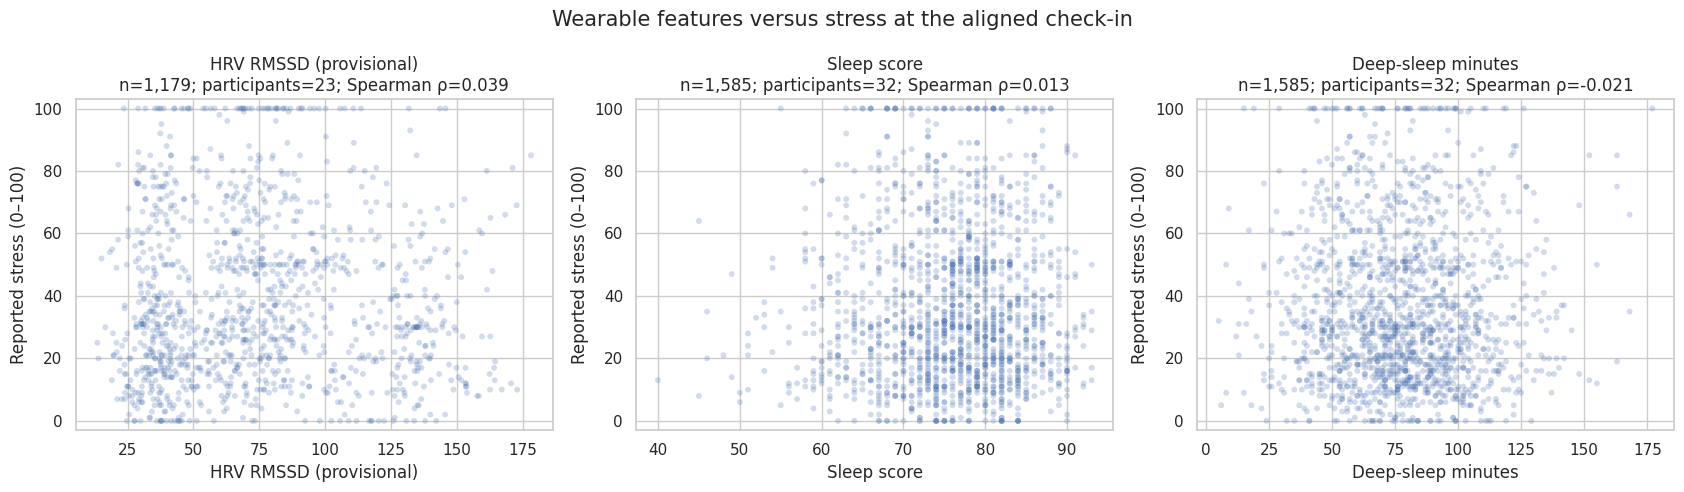

Dots are repeated observations from participants, not independent samples. HRV timing remains provisional; these plots do not show causation.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plot_features = {
    "hrv_rmssd_median_24h_provisional": "HRV RMSSD (provisional)",
    "sleep_overall_score": "Sleep score",
    "sleep_deep_minutes": "Deep-sleep minutes",
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (feature, label) in zip(axes, plot_features.items()):
    paired = (
        feature_table[["participant_id", feature, "stress"]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    rho = paired[feature].corr(paired["stress"], method="spearman")

    ax.scatter(
        paired[feature],
        paired["stress"],
        alpha=0.25,
        s=18,
        edgecolors="none",
    )

    ax.set_title(
        f"{label}\n"
        f"n={len(paired):,}; "
        f"participants={paired['participant_id'].nunique()}; "
        f"Spearman ρ={rho:.3f}"
    )
    ax.set_xlabel(label)
    ax.set_ylabel("Reported stress (0–100)")
    ax.set_ylim(-3, 103)

fig.suptitle(
    "Wearable features versus stress at the aligned check-in",
    fontsize=15,
)

fig.tight_layout()
plt.show()

print(
    "Dots are repeated observations from participants, not independent samples. "
    "HRV timing remains provisional; these plots do not show causation."
)

Participants selected by joint data availability:


,participant_id,joint_checkins
8,24,99
19,5,98


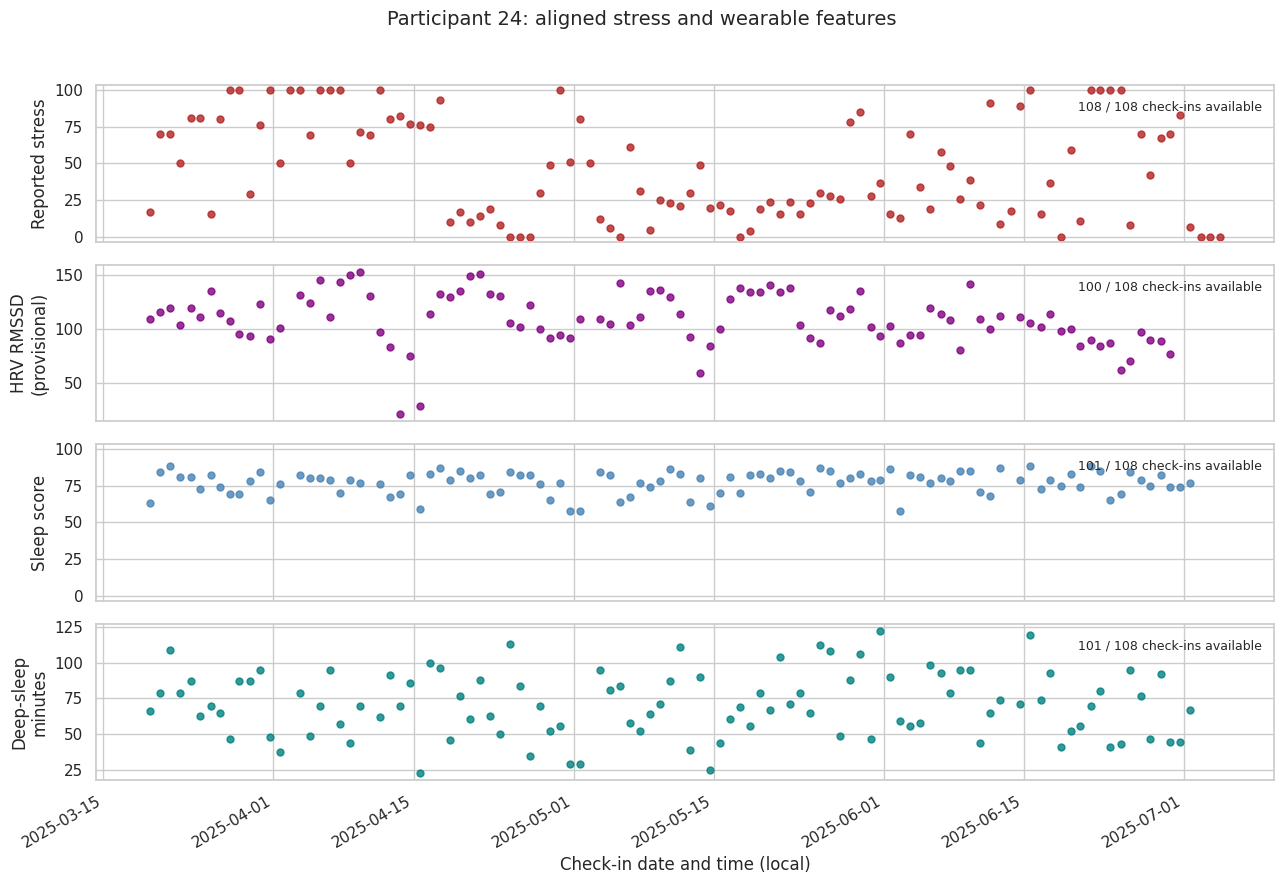

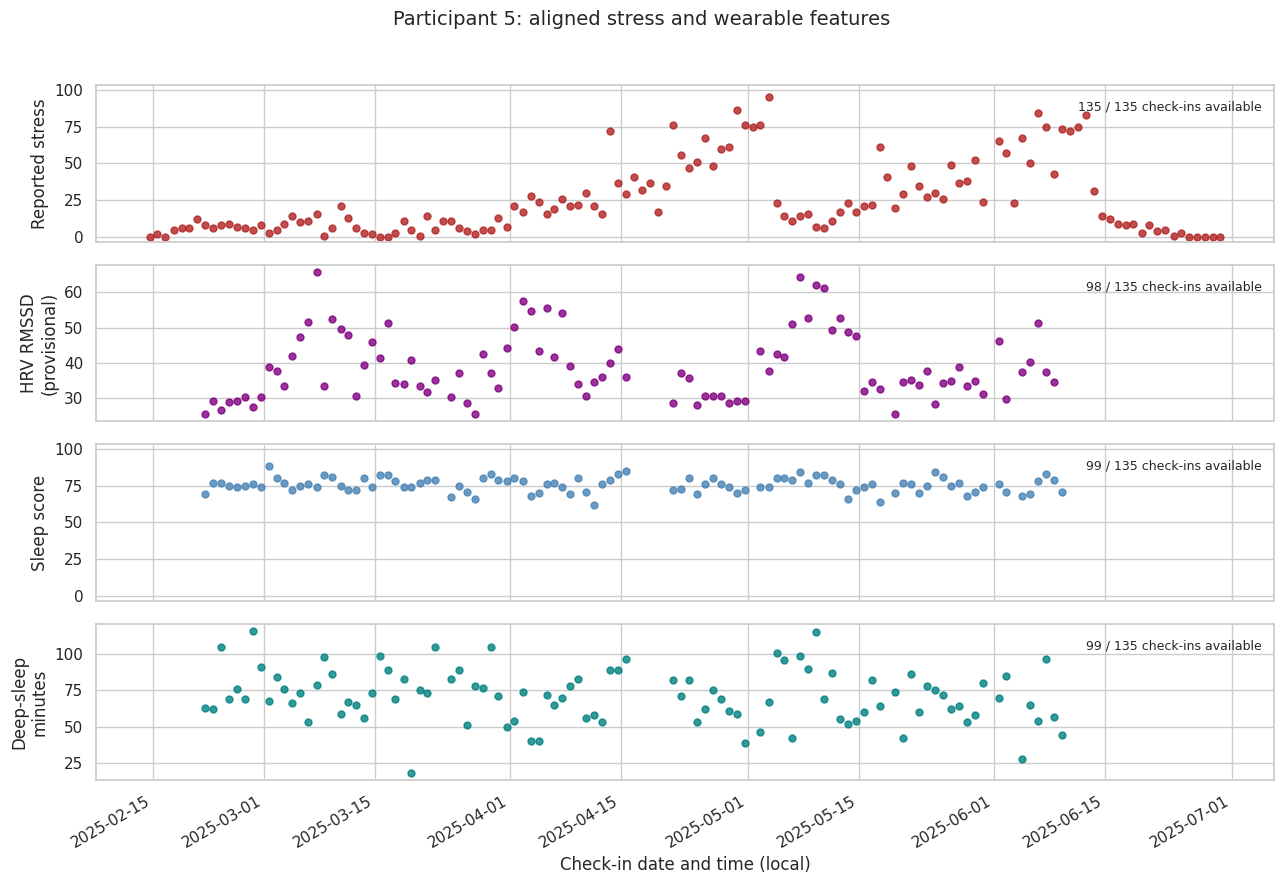

Wearable values are plotted at the check-in they were assigned to, not their original measurement time. Missing values are not imputed. The same sleep record may be reused by the documented alignment rule.


In [ ]:
timeline_required = [
    "stress",
    "hrv_rmssd_median_24h_provisional",
    "sleep_overall_score",
    "sleep_deep_minutes",
]

joint_available = feature_table[timeline_required].notna().all(axis=1)

timeline_counts = (
    feature_table.loc[joint_available]
    .groupby("participant_id")
    .size()
    .rename("joint_checkins")
    .reset_index()
    .sort_values(
        ["joint_checkins", "participant_id"],
        ascending=[False, True],
    )
)

assert len(timeline_counts) >= 2, (
    "Fewer than two participants have joint stress, HRV and sleep observations."
)

selected_participants = timeline_counts.head(2)["participant_id"].tolist()

print("Participants selected by joint data availability:")
display(timeline_counts.head(2))

timeline_panels = [
    ("stress", "Reported stress", "firebrick"),
    ("hrv_rmssd_median_24h_provisional", "HRV RMSSD\n(provisional)", "purple"),
    ("sleep_overall_score", "Sleep score", "steelblue"),
    ("sleep_deep_minutes", "Deep-sleep\nminutes", "teal"),
]

for participant in selected_participants:
    person = (
        feature_table.loc[
            feature_table["participant_id"].eq(participant)
        ]
        .sort_values("checkin_local")
    )

    fig, axes = plt.subplots(
        4, 1, figsize=(13, 9), sharex=True
    )

    for ax, (feature, label, color) in zip(axes, timeline_panels):
        available = person[feature].notna()

        ax.scatter(
            person.loc[available, "checkin_local"],
            person.loc[available, feature],
            color=color,
            s=25,
            alpha=0.8,
        )

        ax.set_ylabel(label)
        ax.text(
            0.99, 0.90,
            f"{available.sum()} / {len(person)} check-ins available",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=9,
        )

        if feature in ["stress", "sleep_overall_score"]:
            ax.set_ylim(-3, 103)

    axes[-1].set_xlabel("Check-in date and time (local)")
    fig.suptitle(
        f"Participant {participant}: aligned stress and wearable features",
        fontsize=14,
    )

    fig.autofmt_xdate()
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

print(
    "Wearable values are plotted at the check-in they were assigned to, "
    "not their original measurement time. Missing values are not imputed. "
    "The same sleep record may be reused by the documented alignment rule."
)

## MW-201: Findings and limitations

### Dataset and alignment

The dataset contains 3,133 questionnaires from 35 participants; 32
participants have wearable files. Questionnaire counts range from 7 to
135 per participant. Overall, 24.5% of reports score at least 50 on the
0–100 reported-stress scale. This threshold is a project convention,
not a clinical diagnosis.

A provisional feature table preserves one row per check-in. Steps and
activity are selected from local midnight to before the check-in, using
the implemented interval buffers. Sleep uses the latest timestamp within
the preceding 36 hours. HRV uses the preceding 24 hours under a provisional
local-time interpretation, excluding participants with multiple observed
questionnaire UTC offsets.

### Main findings

1. **Wearable availability is incomplete.** Steps are available for 2,173
   check-ins, activity for 2,203, sleep for 1,585, and provisional HRV for
   1,179. Only 1,141 check-ins across 23 participants contain all five
   candidate features. Missing measurements were not replaced with zero.

2. **Complete-feature observations have a different stress distribution.**
   Mean reported stress is 38.79 for complete-feature check-ins and 30.05
   when at least one feature is missing. Complete-case analysis therefore
   selects a different observed sample; these results do not establish
   the cause of missingness.

3. **Same-check-in wearable associations are weak.** Pooled Spearman
   correlations range from −0.021 to +0.149. Median participant-level
   correlations are also small, and each feature's participant-correlation
   interquartile range spans zero.

4. **Observation filters do not reveal strong associations.** Requiring
   at least 50% observed activity minutes reduces the pooled active-minutes
   correlation from 0.137 to 0.059 while reducing the sample from 2,203 to
   636 check-ins. Sleep and provisional HRV correlations remain near zero
   under the tested filters. Filtering changes sample composition as well
   as observation support.

5. **Current reported stress has a stronger next-day association than the
   individual wearable features tested.** Across 2,747 next-calendar-day
   pairs, wearable pooled correlations range from −0.002 to +0.112.
   Current stress correlates with next-day stress at 0.619 overall and
   0.570–0.597 on the same rows used for each wearable feature. Excluding
   two pairs outside an exploratory 18–30-hour window leaves the displayed
   correlations unchanged to three decimal places.

### Limitations

- HRV timestamp interpretation remains provisional. Its hourly pattern
  supports, but does not verify, a local-time interpretation.
- Steps are assumed to be interval counts. Sleep timestamp meaning and
  actual data availability times still require confirmation.
- Passing cutoff assertions verifies the implemented selection rules;
  it does not independently establish leakage-free real-time availability.
- Median activity observation covers only 42.2% of the midnight-to-check-in
  window. Unrecorded periods cannot be assumed sedentary or interpreted
  directly as device non-wear.
- HRV coverage values above 1 and nine non-failed Fitbit zero scores remain
  unresolved data-quality questions. Fitbit stress scores were not used
  as predictors.
- Participant correlations require at least 10 paired observations.
  This is an exploratory inclusion rule, not a validated reliability
  threshold.
- Correlations are descriptive. Repeated observations, selection effects,
  and possible confounding limit interpretation.
- The participant timelines were selected by joint data availability;
  they are illustrative and do not represent every participant.
- This analysis does not validate prediction accuracy, personalised
  baseline superiority, or physiological–perceived stress mismatch.

### Implications for the next stage

Reconcile the notebook's alignment rules with the shared preprocessing
script before model development. Evaluate whether wearable features add
information beyond simple baselines. For next-day prediction after today's
check-in, include current reported stress as a reference baseline.

Any personalised baseline features must use earlier observations only.

In [ ]:
from pathlib import Path
from textwrap import dedent

summary_path = Path(EDA_DIR) / "eda_summary.md"

summary_text = dedent("""
# MW-201 EDA Summary

## Scope
Analysis of 3,133 check-ins from 35 SSAQS participants, including
32 participants with wearable files. A provisional check-in-aligned
feature table was constructed without imputing missing measurements.

## Findings
- Feature availability: 2,173 check-ins with steps, 2,203 with activity,
  1,585 with sleep, and 1,179 with provisional HRV.
- All five candidate features are available for 1,141 check-ins across
  23 participants. Mean stress is 38.79 in this subset versus 30.05
  when at least one feature is missing.
- Same-check-in pooled wearable–stress Spearman correlations range
  from -0.021 to +0.149. Participant-level associations are small
  and vary in direction.
- Tested observation-quality filters do not reveal strong associations.
  Median activity observation covers 42.2% of the pre-check-in window.
- Among 2,747 next-calendar-day pairs, wearable correlations with
  next-day stress range from -0.002 to +0.112. Current reported stress
  has a correlation of 0.619 overall and 0.570–0.597 on the same
  observations used for individual wearable comparisons.
- Excluding two pairs outside an exploratory 18–30-hour interval
  leaves the displayed correlations unchanged to three decimal places.

## Alignment rules
- Steps/activity: local midnight to before check-in, with the implemented
  interval buffers; activity counts represent distinct observed minute bins.
- Sleep: latest timestamp within the preceding 36 hours.
- HRV: preceding 24 hours, provisionally interpreting timestamps as local
  time; participants with multiple questionnaire offsets are excluded.
- Missing features remain missing. Fitbit stress scores are not predictors.

## Limitations
HRV timezone, interval/summary timestamp meanings, and real-time data
availability remain unverified. HRV coverage above 1 and nine non-failed
Fitbit zero scores remain unresolved. Cutoff assertions check implemented
rules, not independently verified real-time availability.

Observations repeat within participants, and complete-case filtering
changes the observed stress distribution. Correlations are descriptive;
they do not establish causation, predictive accuracy, personalised-baseline
superiority, or physiological–perceived stress mismatch.

## Next steps
1. Reconcile feature definitions with the runnable shared preprocessing script.
2. Verify timestamp semantics and trace the agreed example check-ins.
3. Agree on prediction target, prediction moment, and evaluation split.
4. Build personal-baseline features using past observations only.
5. Evaluate wearable information against appropriate simple baselines,
   including current stress for next-day prediction after today's check-in.
""").strip() + "\n"

# Preserve a previous summary if its content differs.
if summary_path.exists():
    previous = summary_path.read_text(encoding="utf-8")
    if previous != summary_text:
        backup = summary_path.with_name(
            f"eda_summary_backup_{pd.Timestamp.now():%Y%m%d_%H%M%S_%f}.md"
        )
        backup.write_text(previous, encoding="utf-8")
        print("Previous summary backed up to:", backup)

summary_path.write_text(summary_text, encoding="utf-8")

print("Summary saved to:", summary_path)
print("Remember to save the notebook with the new plots and Markdown cell.")

Summary saved to: /content/MindWatch-IE08/EDA/eda_summary.md
Remember to save the notebook with the new plots and Markdown cell.
